<a href="https://colab.research.google.com/github/surajgade17/solubility-prediction-delaney/blob/main/delaney_qsar_upgrade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Delaney Solubility QSAR (upgrade)
Goal: compare random and scaffold splits using Morgan fingerprints, then benchmark several models with cross-validation.
## Step 1: Load data, build fingerprints, make two splits
A scaffold split keeps molecules with the same core structure on the same side of the split, so the test set is harder and more honest.

In [1]:
!pip -q install rdkit
import pandas as pd, numpy as np
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
df = pd.read_csv(url)
df = df.rename(columns={"measured log solubility in mols per litre": "logS"})[["smiles", "logS"]]
df["mol"] = df.smiles.apply(Chem.MolFromSmiles)
print("Invalid SMILES:", df.mol.isna().sum(), "| Molecules:", len(df))

# Morgan fingerprints (radius 2, 2048 bits)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([gen.GetFingerprintAsNumPy(m) for m in df.mol])
y = df.logS.values

# Random split
tr_r, te_r = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)

# Scaffold split (largest scaffold groups go to training first)
df["scaffold"] = df.mol.apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m))
groups = sorted(df.groupby("scaffold").indices.values(), key=lambda g: (-len(g), g[0]))
tr_s, te_s = [], []
for g in groups:
    (tr_s if len(tr_s) + len(g) <= 0.8 * len(df) else te_s).extend(g)

print("Random split   -> train", len(tr_r), "| test", len(te_r))
print("Scaffold split -> train", len(tr_s), "| test", len(te_s))
print("Scaffolds shared between train and test:",
      len(set(df.scaffold.iloc[tr_s]) & set(df.scaffold.iloc[te_s])), "(should be 0)")

Invalid SMILES: 0 | Molecules: 1128
Random split   -> train 902 | test 226
Scaffold split -> train 902 | test 226
Scaffolds shared between train and test: 0 (should be 0)


## Step 2: Compare models on both splits
Four models are trained on the same fingerprints: a mean baseline (always predicts the average), Random Forest, XGBoost and SVR. Each is tested on the random split and the scaffold split.
R² closer to 1 is better. RMSE and MAE closer to 0 are better.

In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

models = {
    "Mean baseline": DummyRegressor(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
    "SVR (RBF)": SVR(C=5, kernel="rbf"),
}
splits = {"Random": (tr_r, te_r), "Scaffold": (tr_s, te_s)}

rows = []
for sname, (tr, te) in splits.items():
    for mname, model in models.items():
        model.fit(X[tr], y[tr])
        p = model.predict(X[te])
        rows.append({"split": sname, "model": mname,
                     "R2": r2_score(y[te], p),
                     "RMSE": mean_squared_error(y[te], p) ** 0.5,
                     "MAE": mean_absolute_error(y[te], p)})

results = pd.DataFrame(rows).round(3)
results

,split,model,R2,RMSE,MAE
0,Random,Mean baseline,-0.000,2.174,1.732
1,Random,Random Forest,0.716,1.159,0.875
2,Random,XGBoost,0.757,1.073,0.812
3,Random,SVR (RBF),0.785,1.009,0.729
4,Scaffold,Mean baseline,-0.212,2.242,1.685
5,Scaffold,Random Forest,0.315,1.685,1.293
6,Scaffold,XGBoost,0.402,1.575,1.219
7,Scaffold,SVR (RBF),0.467,1.487,1.144


## Step 3: Cross-validation and feature sets
Instead of one split, each model is scored on 5 folds, and I report mean ± standard deviation.
- Random 5-fold: molecules are shuffled into folds.
- Scaffold 5-fold: molecules with the same scaffold stay in the same fold. Acyclic molecules (no scaffold) are each treated as their own group, so they don't all land in one fold.
Three feature sets: Morgan fingerprints, 8 RDKit descriptors, and both combined.

In [3]:
from sklearn.model_selection import KFold, GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors

def desc(m):
    heavy = m.GetNumHeavyAtoms()
    return [Crippen.MolLogP(m), Descriptors.MolWt(m), rdMolDescriptors.CalcTPSA(m),
            rdMolDescriptors.CalcNumHBD(m), rdMolDescriptors.CalcNumHBA(m),
            rdMolDescriptors.CalcNumRotatableBonds(m), rdMolDescriptors.CalcNumRings(m),
            sum(a.GetIsAromatic() for a in m.GetAtoms()) / heavy]

D = np.array([desc(m) for m in df.mol])
n_desc = D.shape[1]
feature_sets = {"Fingerprint": X, "Descriptors": D, "Both": np.hstack([D, X])}

def scaler_for(name):
    if name == "Fingerprint":
        return FunctionTransformer()
    if name == "Descriptors":
        return StandardScaler()
    return ColumnTransformer([("s", StandardScaler(), list(range(n_desc)))], remainder="passthrough")

def model_for(name):
    return {"Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
            "XGBoost": XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.05,
                                    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
            "SVR (RBF)": SVR(C=5, kernel="rbf")}[name]

# acyclic molecules each get their own group
scaf = np.where(df.scaffold.values == "", "acyclic_" + df.index.astype(str), df.scaffold.values)
groups = pd.factorize(scaf)[0]
cvs = {"Random 5-fold": (KFold(5, shuffle=True, random_state=42), None),
       "Scaffold 5-fold": (GroupKFold(5), groups)}
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error"}

rows = []
for cname, (cv, g) in cvs.items():
    for fname, Xf in feature_sets.items():
        for mname in ["Random Forest", "XGBoost", "SVR (RBF)"]:
            pipe = make_pipeline(scaler_for(fname), model_for(mname))
            s = cross_validate(pipe, Xf, y, cv=cv, groups=g, scoring=scoring)
            rows.append({"cv": cname, "features": fname, "model": mname,
                         "R2_mean": s["test_r2"].mean(), "R2_sd": s["test_r2"].std(),
                         "RMSE_mean": -s["test_rmse"].mean(), "RMSE_sd": s["test_rmse"].std()})
cv_results = pd.DataFrame(rows).round(3)
cv_results.sort_values(["cv", "R2_mean"], ascending=[True, False])

,cv,features,model,R2_mean,R2_sd,RMSE_mean,RMSE_sd
8,Random 5-fold,Both,SVR (RBF),0.911,0.013,0.621,0.056
7,Random 5-fold,Both,XGBoost,0.907,0.011,0.636,0.049
6,Random 5-fold,Both,Random Forest,0.894,0.018,0.678,0.070
4,Random 5-fold,Descriptors,XGBoost,0.892,0.016,0.684,0.063
3,Random 5-fold,Descriptors,Random Forest,0.886,0.016,0.705,0.062
5,Random 5-fold,Descriptors,SVR (RBF),0.885,0.015,0.706,0.059
2,Random 5-fold,Fingerprint,SVR (RBF),0.764,0.016,1.014,0.023
1,Random 5-fold,Fingerprint,XGBoost,0.699,0.018,1.145,0.032
0,Random 5-fold,Fingerprint,Random Forest,0.673,0.022,1.194,0.035
17,Scaffold 5-fold,Both,SVR (RBF),0.858,0.043,0.742,0.079


## Step 4: y-randomization, figures and saved outputs
y-randomization shuffles the solubility values. A model that learned real chemistry should drop to R² near 0 or below. If it still scores well, something is wrong (leakage).

y-randomized R2 (5 shuffles): [-0.179 -0.153 -0.099 -0.131 -0.128] | mean -0.138


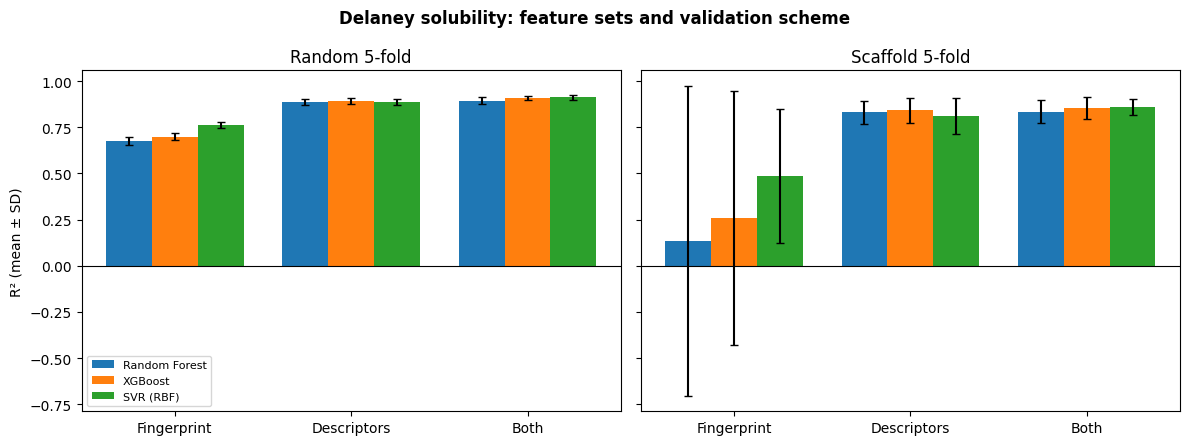

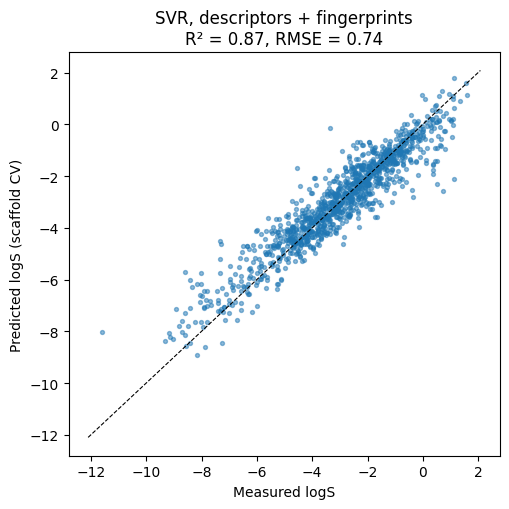

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt

# ---- y-randomization (scaffold CV, Both + SVR)
rng = np.random.default_rng(0)
Xb = feature_sets["Both"]
yr = []
for _ in range(5):
    ys = rng.permutation(y)
    pipe = make_pipeline(scaler_for("Both"), model_for("SVR (RBF)"))
    s = cross_validate(pipe, Xb, ys, cv=GroupKFold(5), groups=groups, scoring={"r2": "r2"})
    yr.append(s["test_r2"].mean())
print("y-randomized R2 (5 shuffles):", np.round(yr, 3), "| mean", round(np.mean(yr), 3))

# ---- Figure 1: CV comparison
fs = ["Fingerprint", "Descriptors", "Both"]
ms = ["Random Forest", "XGBoost", "SVR (RBF)"]
w = 0.26
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, cname in zip(ax, ["Random 5-fold", "Scaffold 5-fold"]):
    sub = cv_results[cv_results.cv == cname]
    for j, m in enumerate(ms):
        v = sub[sub.model == m].set_index("features").loc[fs]
        a.bar(np.arange(3) + (j - 1) * w, v.R2_mean, w, yerr=v.R2_sd, capsize=3, label=m)
    a.set_xticks(range(3)); a.set_xticklabels(fs)
    a.set_title(cname); a.axhline(0, color="black", lw=0.8)
ax[0].set_ylabel("R² (mean ± SD)"); ax[0].legend(fontsize=8)
plt.suptitle("Delaney solubility: feature sets and validation scheme", fontweight="bold")
plt.tight_layout(); plt.savefig("delaney_cv_comparison.png", dpi=150); plt.show()

# ---- Figure 2: predicted vs measured (scaffold CV)
pipe = make_pipeline(scaler_for("Both"), model_for("SVR (RBF)"))
pred = cross_val_predict(pipe, Xb, y, cv=GroupKFold(5), groups=groups)
r2 = r2_score(y, pred); rmse = mean_squared_error(y, pred) ** 0.5
plt.figure(figsize=(5.2, 5.2))
plt.scatter(y, pred, s=8, alpha=0.5)
lo, hi = y.min() - 0.5, y.max() + 0.5
plt.plot([lo, hi], [lo, hi], "k--", lw=0.8)
plt.xlabel("Measured logS"); plt.ylabel("Predicted logS (scaffold CV)")
plt.title(f"SVR, descriptors + fingerprints\nR² = {r2:.2f}, RMSE = {rmse:.2f}")
plt.tight_layout(); plt.savefig("delaney_pred_vs_actual.png", dpi=150); plt.show()

# ---- Save files
results.to_csv("single_split_results.csv", index=False)
cv_results.to_csv("cv_results.csv", index=False)
from google.colab import files
for f in ["delaney_cv_comparison.png", "delaney_pred_vs_actual.png", "cv_results.csv", "single_split_results.csv"]:
    files.download(f)